In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv('missing_value_imputation_data.csv')

In [4]:
df.shape

(3554, 19)

In [5]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8542.0,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6477.0,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8


In [6]:
train_df = df.drop(columns=['society','price_per_sqft'])

In [7]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,sohna road,0.35,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6
1,flat,sector 56,2.05,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47
2,flat,sector 90,1.25,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6
3,flat,sector 56,1.45,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47
4,flat,sector 92,0.66,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8


<Axes: >

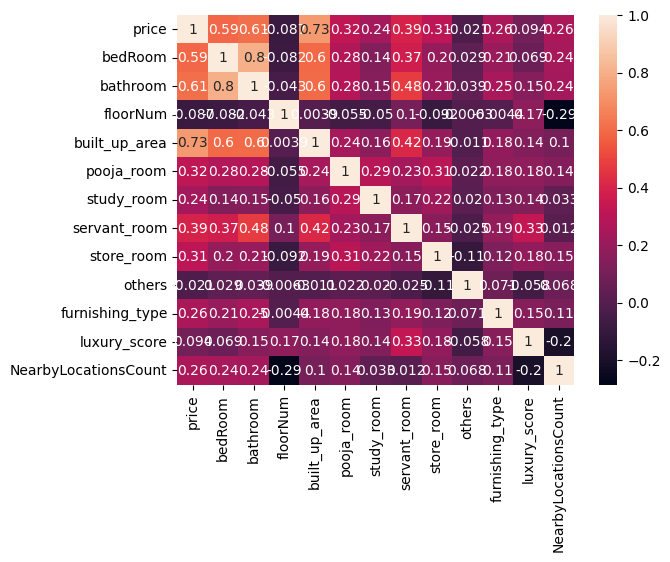

In [8]:
sns.heatmap(train_df.corr(numeric_only=True), annot=True)

In [9]:
train_df.corr(numeric_only=True)['price'].sort_values(ascending=False)

price                   1.000000
built_up_area           0.732518
bathroom                0.611177
bedRoom                 0.589277
servant_room            0.392933
pooja_room              0.318045
store_room              0.309969
NearbyLocationsCount    0.260136
furnishing_type         0.255564
study_room              0.240468
luxury_score            0.093605
others                 -0.021225
floorNum               -0.086978
Name: price, dtype: float64

In [10]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,sohna road,0.35,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6
1,flat,sector 56,2.05,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47
2,flat,sector 90,1.25,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6
3,flat,sector 56,1.45,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47
4,flat,sector 92,0.66,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8


## luxury_score

<Axes: ylabel='luxury_score'>

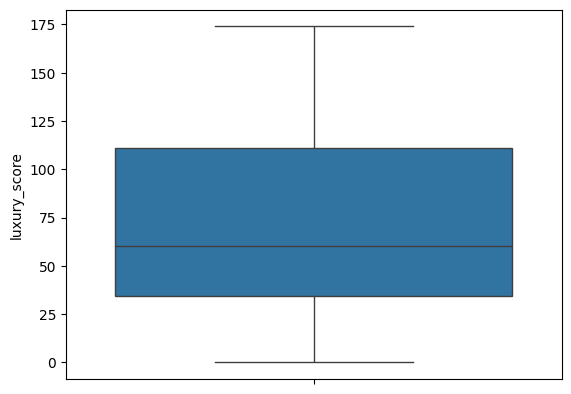

In [11]:
sns.boxplot(df['luxury_score'])

In [12]:
def categorize_luxury(score):
    if 0 <= score < 50:
        return "Low"
    elif 50 <= score < 150:
        return "Medium"
    elif 150 <= score <= 175:
        return "High"
    else:
        return None  # or "Undefined" or any other label for scores outside the defined bins

In [13]:
train_df['luxury_category'] = train_df['luxury_score'].apply(categorize_luxury)

In [14]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,luxury_category
0,flat,sohna road,0.35,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6,Low
1,flat,sector 56,2.05,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47,Low
2,flat,sector 90,1.25,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6,Medium
3,flat,sector 56,1.45,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47,High
4,flat,sector 92,0.66,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8,Low


## floorNum

<Axes: ylabel='floorNum'>

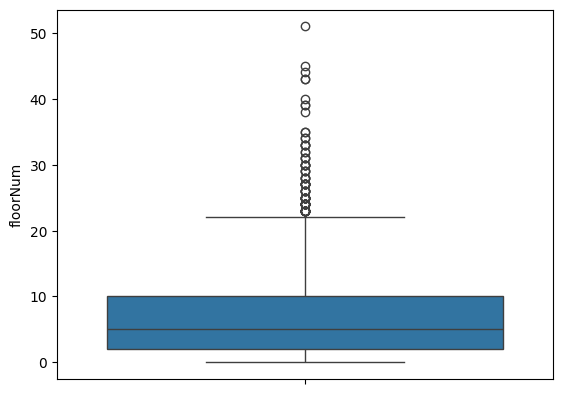

In [15]:
sns.boxplot(df['floorNum'])

In [16]:
def categorize_floor(floor):
    if 0 <= floor <= 2:
        return "Low Floor"
    elif 3 <= floor <= 10:
        return "Mid Floor"
    elif 11 <= floor <= 51:
        return "High Floor"
    else:
        return None  # or "Undefined" or any other label for floors outside the defined bins


In [17]:
train_df['floor_category'] = train_df['floorNum'].apply(categorize_floor)

In [18]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,luxury_category,floor_category
0,flat,sohna road,0.35,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6,Low,Mid Floor
1,flat,sector 56,2.05,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47,Low,Mid Floor
2,flat,sector 90,1.25,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6,Medium,High Floor
3,flat,sector 56,1.45,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47,High,Mid Floor
4,flat,sector 92,0.66,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8,Low,High Floor


## NearbyLocationsCount

In [19]:
train_df['NearbyLocationsCount'].describe()

count    3554.000000
mean       17.657569
std        15.213929
min         0.000000
25%         9.000000
50%        11.000000
75%        15.000000
max        50.000000
Name: NearbyLocationsCount, dtype: float64

In [20]:
train_df['NearbyLocationsCount'].value_counts().sort_index()

NearbyLocationsCount
0     157
3      39
4      67
5      32
6     152
7     137
8     261
9     216
10    487
11    316
12    104
13    216
14    137
15    425
16      6
17      6
18      9
19      1
20      2
21      4
22      3
23      4
24      2
25      3
26     12
27     28
28      2
29      5
30      3
31      5
32      6
33      4
34      5
35      1
36      3
37      2
38      2
39      1
41      3
42      5
43     21
44     66
45     51
46    123
47    109
48     86
49    106
50    119
Name: count, dtype: int64

In [21]:
def categorize_nearby(count):
    if pd.isna(count):
        return None
    elif count <= 9:
        return 'Low'
    elif count <= 15:
        return 'Medium'
    else:
        return 'High'

train_df['NearbyLocationsCategory'] = (
    train_df['NearbyLocationsCount'].apply(categorize_nearby)
)

In [22]:
train_df['NearbyLocationsCategory'].value_counts()

NearbyLocationsCategory
Medium    1685
Low       1061
High       808
Name: count, dtype: int64

In [23]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount,luxury_category,floor_category,NearbyLocationsCategory
0,flat,sohna road,0.35,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6,Low,Mid Floor,Low
1,flat,sector 56,2.05,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47,Low,Mid Floor,High
2,flat,sector 90,1.25,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6,Medium,High Floor,Low
3,flat,sector 56,1.45,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47,High,Mid Floor,High
4,flat,sector 92,0.66,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8,Low,High Floor,Low


In [24]:
train_df.drop(columns=['floorNum','luxury_score','NearbyLocationsCount'],inplace=True)

In [25]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_category,floor_category,NearbyLocationsCategory
0,flat,sohna road,0.35,2,2,2,Relatively New,556.0,0,0,0,0,0,0,Low,Mid Floor,Low
1,flat,sector 56,2.05,4,4,3+,Moderately Old,2667.0,0,0,0,0,0,0,Low,Mid Floor,High
2,flat,sector 90,1.25,3,3,3+,Relatively New,1700.0,1,0,1,0,0,0,Medium,High Floor,Low
3,flat,sector 56,1.45,3,3,3+,Old Property,1900.0,1,1,1,0,1,0,High,Mid Floor,High
4,flat,sector 92,0.66,3,2,2,Relatively New,1473.0,0,0,0,0,0,1,Low,High Floor,Low


In [26]:
from sklearn.preprocessing import OrdinalEncoder

# Create a copy of the original data for label encoding
data_label_encoded = train_df.copy()

categorical_cols = train_df.select_dtypes(include=['object']).columns

# Apply label encoding to categorical columns
for col in categorical_cols:
    oe = OrdinalEncoder()
    data_label_encoded[col] = oe.fit_transform(data_label_encoded[[col]])
    print(oe.categories_)

# Splitting the dataset into training and testing sets
X_label = data_label_encoded.drop('price', axis=1)
y_label = data_label_encoded['price']

[array(['flat', 'house'], dtype=object)]
[array(['dwarka expressway', 'gwal pahari', 'manesar', 'sector 1',
       'sector 102', 'sector 103', 'sector 104', 'sector 105',
       'sector 106', 'sector 107', 'sector 108', 'sector 109',
       'sector 10a', 'sector 11', 'sector 110', 'sector 111',
       'sector 112', 'sector 113', 'sector 12', 'sector 13', 'sector 14',
       'sector 15', 'sector 17', 'sector 17a', 'sector 17b', 'sector 2',
       'sector 21', 'sector 22', 'sector 23', 'sector 24', 'sector 25',
       'sector 26', 'sector 27', 'sector 28', 'sector 3',
       'sector 3 phase 2', 'sector 3 phase 3 extension', 'sector 30',
       'sector 31', 'sector 33', 'sector 36', 'sector 36a', 'sector 37',
       'sector 37c', 'sector 37d', 'sector 38', 'sector 39', 'sector 4',
       'sector 40', 'sector 41', 'sector 43', 'sector 45', 'sector 46',
       'sector 47', 'sector 48', 'sector 49', 'sector 5', 'sector 50',
       'sector 51', 'sector 52', 'sector 53', 'sector 54', 'sector 5

In [27]:
X_label.sample(5)

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_category,floor_category,NearbyLocationsCategory
2642,0.0,72.0,2,2,2.0,3.0,1400.0,0,0,0,0,0,0,1.0,1.0,2.0
1692,0.0,82.0,2,2,2.0,3.0,1084.0,0,0,0,0,1,0,1.0,2.0,2.0
1829,0.0,4.0,3,4,4.0,3.0,1757.0,0,0,1,0,0,0,2.0,0.0,2.0
1510,1.0,26.0,3,3,2.0,2.0,972.0,0,0,0,0,0,0,1.0,2.0,0.0
1879,0.0,105.0,3,3,3.0,3.0,1765.0,0,0,1,0,0,0,2.0,2.0,2.0


In [28]:
y_label.sample(6)

2376    1.59
138     2.90
1206    0.85
1224    1.10
2439    0.30
1679    1.08
Name: price, dtype: float64

## Correlation Analysis

<Axes: >

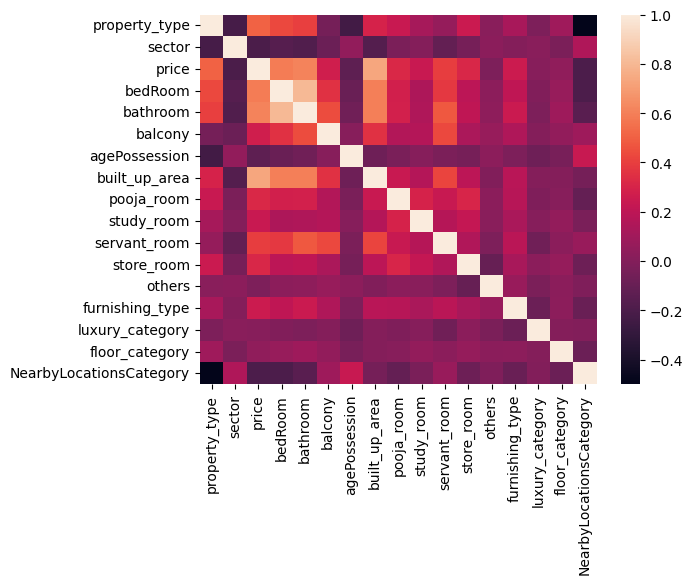

In [29]:
sns.heatmap(data_label_encoded.corr())

In [30]:
fi_df1 = data_label_encoded.corr()['price'].iloc[1:].to_frame().reset_index().rename(columns={'index':'feature','price':'corr_coeff'})
fi_df1

,feature,corr_coeff
0,sector,-0.203272
1,price,1.000000
2,bedRoom,0.589277
3,bathroom,0.611177
4,balcony,0.269650
5,agePossession,-0.134404
6,built_up_area,0.732518
7,pooja_room,0.318045
8,study_room,0.240468
9,servant_room,0.392933


## Random Forest Feature Importance

In [31]:
from sklearn.ensemble import RandomForestRegressor

rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df2 = pd.DataFrame({
    'feature': X_label.columns,
    'rf_importance': rf_label.feature_importances_
}).sort_values(by='rf_importance', ascending=False)

fi_df2

,feature,rf_importance
6,built_up_area,0.644680
0,property_type,0.103388
1,sector,0.100841
2,bedRoom,0.027823
9,servant_room,0.021983
3,bathroom,0.021965
5,agePossession,0.015985
4,balcony,0.012139
15,NearbyLocationsCategory,0.012061
10,store_room,0.008485


##  Gradient Boosting Feature importances

In [32]:
from sklearn.ensemble import GradientBoostingRegressor

gb_label = GradientBoostingRegressor()
gb_label.fit(X_label, y_label)

# Extract feature importance scores for label encoded data
fi_df3 = pd.DataFrame({
    'feature': X_label.columns,
    'gb_importance': gb_label.feature_importances_
}).sort_values(by='gb_importance', ascending=False)

fi_df3

,feature,gb_importance
6,built_up_area,0.672613
1,sector,0.106314
0,property_type,0.099899
2,bedRoom,0.035313
3,bathroom,0.033243
9,servant_room,0.020947
10,store_room,0.013304
5,agePossession,0.005947
13,luxury_category,0.003024
4,balcony,0.002242


## Permutation Importance

In [33]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

X_train_label, X_test_label, y_train_label, y_test_label = train_test_split(X_label, y_label, test_size=0.2, random_state=42)

# Train a Random Forest regressor on label encoded data
rf_label = RandomForestRegressor(n_estimators=100, random_state=42)
rf_label.fit(X_train_label, y_train_label)

# Calculate Permutation Importance
perm_importance = permutation_importance(rf_label, X_test_label, y_test_label, n_repeats=30, random_state=42)

# Organize results into a DataFrame
fi_df4 = pd.DataFrame({
    'feature': X_label.columns,
    'permutation_importance': perm_importance.importances_mean
}).sort_values(by='permutation_importance', ascending=False)

fi_df4

,feature,permutation_importance
6,built_up_area,0.821854
0,property_type,0.201594
1,sector,0.166649
9,servant_room,0.017825
2,bedRoom,0.009680
15,NearbyLocationsCategory,0.008970
4,balcony,0.006564
3,bathroom,0.004819
8,study_room,0.003760
10,store_room,0.003227


## Technique 5 - LASSO

In [34]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_label)

# Train a LASSO regression model
# We'll use a relatively small value for alpha (the regularization strength)
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_scaled, y_label)

# Extract coefficients
fi_df5 = pd.DataFrame({
    'feature': X_label.columns,
    'lasso_coeff': lasso.coef_
}).sort_values(by='lasso_coeff', ascending=False)

fi_df5

,feature,lasso_coeff
6,built_up_area,1.394286
0,property_type,0.680307
3,bathroom,0.293602
10,store_room,0.209606
9,servant_room,0.185703
12,furnishing_type,0.184371
8,study_room,0.171425
7,pooja_room,0.075063
13,luxury_category,0.058858
2,bedRoom,0.049399


##  RFE

In [35]:
# RFE recursive feature elimination
from sklearn.feature_selection import RFE

estimator = RandomForestRegressor()

# Apply RFE on the label-encoded and standardized training data
selector_label = RFE(estimator, n_features_to_select=X_label.shape[1], step=1)
selector_label = selector_label.fit(X_label, y_label)

# Get the selected features based on RFE
selected_features = X_label.columns[selector_label.support_]

# Extract the coefficients for the selected features from the underlying linear regression model
selected_coefficients = selector_label.estimator_.feature_importances_

# Organize the results into a DataFrame
fi_df6 = pd.DataFrame({
    'feature': selected_features,
    'rfe_score': selected_coefficients
}).sort_values(by='rfe_score', ascending=False)

fi_df6

,feature,rfe_score
6,built_up_area,0.641025
1,sector,0.103422
0,property_type,0.103256
2,bedRoom,0.028236
3,bathroom,0.024944
9,servant_room,0.017517
5,agePossession,0.015894
4,balcony,0.011617
15,NearbyLocationsCategory,0.011342
10,store_room,0.010611


## Linear Regression Weights

In [36]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_scaled, y_label)

# Extract coefficients
fi_df7 = pd.DataFrame({
    'feature': X_label.columns,
    'reg_coeffs': lin_reg.coef_
}).sort_values(by='reg_coeffs', ascending=False)

fi_df7

,feature,reg_coeffs
6,built_up_area,1.396942
0,property_type,0.674483
3,bathroom,0.300927
10,store_room,0.214571
9,servant_room,0.195638
12,furnishing_type,0.192665
8,study_room,0.179794
7,pooja_room,0.078247
13,luxury_category,0.069507
2,bedRoom,0.051614


In [37]:
# Shap - explanable ai 

import shap

# Compute SHAP values using the trained Random Forest model
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_label, y_label)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_label)

# Summing the absolute SHAP values across all samples to get an overall measure of feature importance
shap_sum = np.abs(shap_values).mean(axis=0)

shap_values

array([[-1.74412473e-01, -3.92701032e-01, -4.59662667e-02, ...,
        -2.94937674e-03, -5.44938839e-03, -1.39953887e-02],
       [-5.28602348e-01,  4.43040151e-01, -2.03211045e-03, ...,
         5.72613949e-04, -6.61426407e-02, -8.42230926e-01],
       [-2.30403925e-01, -6.03114621e-01, -9.13761297e-03, ...,
         2.27524812e-03,  1.69057214e-02, -1.81955970e-02],
       ...,
       [-1.89451561e-01,  6.60817360e-02, -5.36604765e-02, ...,
        -1.38261315e-02, -6.68114490e-03, -7.97871904e-02],
       [ 7.30183993e-01, -1.65112535e+00, -1.62800529e-02, ...,
        -4.18717479e-02, -1.81715234e-01, -1.02303724e-01],
       [ 1.38469057e+00,  2.96667165e-01, -4.27315301e-03, ...,
         2.06728017e-02, -2.26235166e-03,  1.74450468e-02]],
      shape=(3554, 16))

In [38]:
fi_df8 = pd.DataFrame({
    'feature': X_label.columns,
    'SHAP_score': np.abs(shap_values).mean(axis=0)
}).sort_values(by='SHAP_score', ascending=False)

fi_df8

,feature,SHAP_score
6,built_up_area,1.247931
0,property_type,0.472521
1,sector,0.384903
3,bathroom,0.102217
9,servant_room,0.093619
2,bedRoom,0.057962
15,NearbyLocationsCategory,0.046701
4,balcony,0.038661
5,agePossession,0.025656
12,furnishing_type,0.024305


In [39]:
final_fi_df = fi_df1.merge(fi_df2,on='feature').merge(fi_df3,on='feature').merge(fi_df4,on='feature').merge(fi_df5,on='feature').merge(fi_df6,on='feature').merge(fi_df7,on='feature').merge(fi_df8,on='feature').set_index('feature')

In [40]:
final_fi_df

,corr_coeff,rf_importance,gb_importance,permutation_importance,lasso_coeff,rfe_score,reg_coeffs,SHAP_score
feature,,,,,,,,
sector,-0.203272,0.100841,0.106314,0.166649,-0.062220,0.103422,-0.070922,0.384903
bedRoom,0.589277,0.027823,0.035313,0.009680,0.049399,0.028236,0.051614,0.057962
bathroom,0.611177,0.021965,0.033243,0.004819,0.293602,0.024944,0.300927,0.102217
balcony,0.269650,0.012139,0.002242,0.006564,-0.021557,0.011617,-0.043854,0.038661
agePossession,-0.134404,0.015985,0.005947,0.002258,-0.036610,0.015894,-0.043657,0.025656
built_up_area,0.732518,0.644680,0.672613,0.821854,1.394286,0.641025,1.396942,1.247931
pooja_room,0.318045,0.004345,0.000581,-0.000664,0.075063,0.004179,0.078247,0.009806
study_room,0.240468,0.005961,0.001533,0.003760,0.171425,0.006503,0.179794,0.016727
servant_room,0.392933,0.021983,0.020947,0.017825,0.185703,0.017517,0.195638,0.093619


In [41]:
# normalize the score
final_fi_df = final_fi_df.divide(final_fi_df.sum(axis=0), axis=1)

In [42]:
final_fi_df[['rf_importance','gb_importance','permutation_importance','rfe_score','SHAP_score']].mean(axis=1).sort_values(ascending=False)

feature
built_up_area              0.711679
sector                     0.137545
bathroom                   0.028467
bedRoom                    0.027699
servant_room               0.025752
NearbyLocationsCategory    0.011795
agePossession              0.011297
balcony                    0.010719
store_room                 0.009576
study_room                 0.005426
floor_category             0.005356
furnishing_type            0.005060
luxury_category            0.004941
pooja_room                 0.002834
others                     0.001855
dtype: float64

In [43]:
# to drop pooja_room , others 
X_label

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_category,floor_category,NearbyLocationsCategory
0,0.0,111.0,2,2,2.0,3.0,556.0,0,0,0,0,0,0,1.0,2.0,1.0
1,0.0,63.0,4,4,4.0,0.0,2667.0,0,0,0,0,0,0,1.0,2.0,0.0
2,0.0,103.0,3,3,4.0,3.0,1700.0,1,0,1,0,0,0,2.0,0.0,1.0
3,0.0,63.0,3,3,4.0,2.0,1900.0,1,1,1,0,1,0,0.0,2.0,0.0
4,0.0,105.0,3,2,2.0,3.0,1473.0,0,0,0,0,0,1,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3549,0.0,78.0,3,4,2.0,3.0,2056.0,0,0,0,0,0,0,0.0,1.0,2.0
3550,1.0,50.0,3,3,2.0,3.0,2700.0,1,0,1,0,0,0,1.0,2.0,0.0
3551,0.0,47.0,2,2,1.0,3.0,944.0,0,0,0,0,0,0,1.0,1.0,0.0
3552,1.0,83.0,5,5,4.0,3.0,3653.0,0,0,1,0,0,0,1.0,0.0,1.0


In [44]:
# with all the cols
from sklearn.model_selection import cross_val_score

rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label, y_label, cv=5, scoring='r2')

In [45]:
scores.mean()

np.float64(0.8216492967346815)

In [47]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['pooja_room', 'others']), y_label, cv=5, scoring='r2')

In [48]:
scores.mean()

np.float64(0.8219787383819096)

In [49]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['luxury_category','pooja_room', 'others']), y_label, cv=5, scoring='r2')

In [50]:
scores.mean()

np.float64(0.8229904200905682)

In [51]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['luxury_category']), y_label, cv=5, scoring='r2')

In [52]:
scores.mean()

np.float64(0.8215421863971862)

In [53]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['pooja_room']), y_label, cv=5, scoring='r2')

In [54]:
scores.mean()

np.float64(0.8211129274880349)

In [55]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

scores = cross_val_score(rf, X_label.drop(columns=['others']), y_label, cv=5, scoring='r2')
scores.mean()

np.float64(0.8215225449374597)

In [56]:
total_col_df = X_label
total_col_df['price'] = y_label

In [57]:
total_col_df.sample()

,property_type,sector,bedRoom,bathroom,balcony,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_category,floor_category,NearbyLocationsCategory,price
2304,1.0,6.0,3,5,4.0,0.0,920.0,0,0,0,0,0,0,2.0,1.0,1.0,1.95


In [59]:
except2_col_df = X_label.drop(columns=['pooja_room', 'others'])
except2_col_df['price'] = y_label

In [60]:
except3_col_df =  X_label.drop(columns=['pooja_room', 'others','luxury_category'])
except2_col_df['price'] = y_label

In [61]:
total_col_df.to_csv('total_cols_feature_selection.csv', index=False)

In [63]:
except2_col_df.to_csv('except2_cols_df_feature_selection.csv',index=True)

In [64]:
except3_col_df.to_csv('except3_cols_df_feature_selection.csv',index=True)

In [65]:
df = pd.read_csv('missing_value_imputation_data.csv')

In [66]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_score,NearbyLocationsCount
0,flat,gls arawali homes,sohna road,0.35,7000.0,2,2,2,5.0,Relatively New,556.0,0,0,0,0,0,0,30,6
1,flat,the lions cghs,sector 56,2.05,8542.0,4,4,3+,8.0,Moderately Old,2667.0,0,0,0,0,0,0,49,47
2,flat,dlf new town heights,sector 90,1.25,6477.0,3,3,3+,17.0,Relatively New,1700.0,1,0,1,0,0,0,65,6
3,flat,sagar apartment,sector 56,1.45,7250.0,3,3,3+,7.0,Old Property,1900.0,1,1,1,0,1,0,166,47
4,flat,sare crescent parc,sector 92,0.66,4977.0,3,2,2,15.0,Relatively New,1473.0,0,0,0,0,0,1,44,8


In [67]:
train_df.head()

,property_type,sector,price,bedRoom,bathroom,balcony,agePossession,built_up_area,pooja_room,study_room,servant_room,store_room,others,furnishing_type,luxury_category,floor_category,NearbyLocationsCategory
0,flat,sohna road,0.35,2,2,2,Relatively New,556.0,0,0,0,0,0,0,Low,Mid Floor,Low
1,flat,sector 56,2.05,4,4,3+,Moderately Old,2667.0,0,0,0,0,0,0,Low,Mid Floor,High
2,flat,sector 90,1.25,3,3,3+,Relatively New,1700.0,1,0,1,0,0,0,Medium,High Floor,Low
3,flat,sector 56,1.45,3,3,3+,Old Property,1900.0,1,1,1,0,1,0,High,Mid Floor,High
4,flat,sector 92,0.66,3,2,2,Relatively New,1473.0,0,0,0,0,0,1,Low,High Floor,Low


In [68]:
train_df.shape

(3554, 17)

In [69]:
train_df.to_csv('for_model_selection_train_df.csv',index=True)